In [6]:
import numpy as np
import matplotlib.pyplot as plt

In [7]:
g1=-2*np.pi*60 # g1 in MHz qubit 1 coupling strength
g2= 2*np.pi*80 # g2 in MHz qubit 2 coupling strength
w_a=2*np.pi*6.5*1e3# cavity frequency in MHz
delta_a=0 #cavity is on resonance with drive frequency
delta_01 =-0.9 * 2*np.pi * 1e3 # Mhz qubit 1 detuning from drive frequency
delta_02 = -1.6 * 2*np.pi * 1e3 # Mhz qubit 2 detuning from drive
k=20 # cavity decay rate in MHz
x1= g1**2/(delta_01) #dispersive shift of qubit 1
x2= g2**2/(delta_02) #dispersive shift of qubit 2
omega_da = 50* 2*np.pi # rabi frequency in MHz

In [8]:
print(x1+x2, x1-x2, -x1+x2, -x1-x2) #dispersive shifts of the cavity frequency for the two qubits in MHz

-50.26548245743669 3.552713678800501e-15 -3.552713678800501e-15 50.26548245743669


In [9]:
def cavity_traj(t, x1, x2):
    lam = 1j*(x1 + x2) - k/2
    return omega_da/lam * (1 - np.exp(lam*t)) # the cavity trajectory I found.

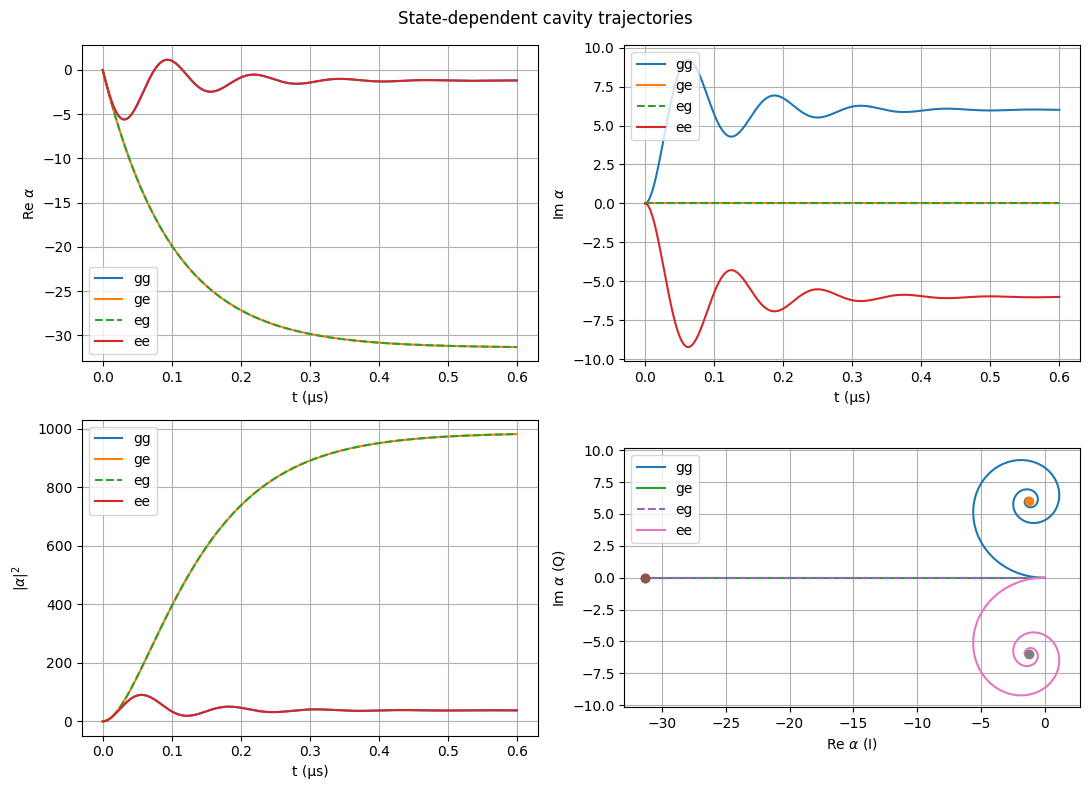

In [ ]:
states = {'gg': (+1, +1), 'ge': (+1, -1), 'eg': (-1, +1), 'ee': (-1, -1)}
t=np.linspace(0,0.6, 1000) # time in µs because the frequencies are in MHz, so the time is in µs. The time is chosen to be 0.5 µs because the cavity decay rate is 20 MHz, so the cavity will decay in 1/k = 1/20 µs = 0.05 µs. Therefore, we want to see the cavity trajectory for a time that is much longer than the cavity decay time.
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
ax_re, ax_im, ax_n, ax_iq = axes.flat

for state, (s1, s2) in states.items():
    traj = cavity_traj(t, s1*x1, s2*x2)
    ls = '--' if state == 'eg' else '-'   

    ax_re.plot(t, traj.real, ls, label=state) #the real part of the cavity trajectory
    ax_im.plot(t, traj.imag, ls, label=state) # the imaginary part of the cavity trajectory
    ax_n.plot(t, np.abs(traj)**2, ls, label=state) # the absolute value squared of the cavity trajectory
    ax_iq.plot(traj.real, traj.imag, ls, label=state) # plots the cavity trajectory in the IQ plane
    ax_iq.plot(traj.real[-1], traj.imag[-1], 'o')  

ax_re.set(xlabel='t (µs)', ylabel=r'Re $\alpha$')
ax_im.set(xlabel='t (µs)', ylabel=r'Im $\alpha$')
ax_n.set(xlabel='t (µs)', ylabel=r'$|\alpha|^2$')
ax_iq.set(xlabel=r'Re $\alpha$ (I)', ylabel=r'Im $\alpha$ (Q)')
ax_iq.set_aspect('equal')

for ax in axes.flat:
    ax.grid(True)
    ax.legend()

fig.suptitle('State-dependent cavity trajectories')
fig.tight_layout()
plt.show()

In [12]:
traj = cavity_traj(t, x1, x2)

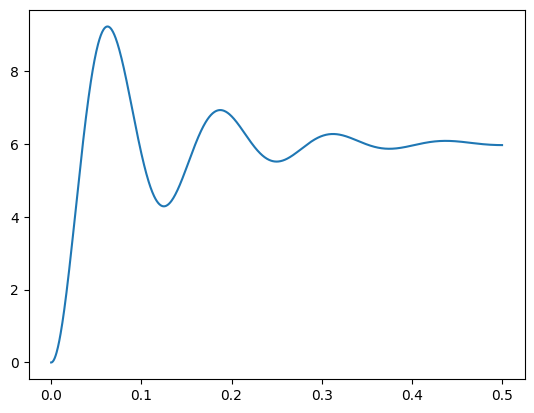

In [13]:
plt.plot(t, traj.imag, label='Im α')

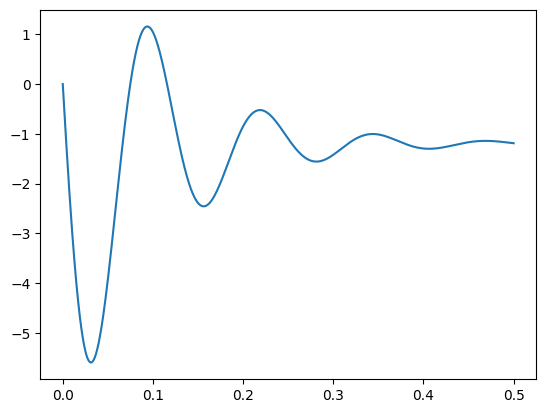

In [14]:
plt.plot(t, traj.real, label='Re α')

In [ ]:
traj.real

array([-0.00000000e+00, -1.56827516e-01, -3.12773353e-01, -4.67744202e-01,
       -6.21648323e-01, -7.74395587e-01, -9.25897520e-01, -1.07606734e+00,
       -1.22482002e+00, -1.37207228e+00, -1.51774266e+00, -1.66175157e+00,
       -1.80402127e+00, -1.94447596e+00, -2.08304175e+00, -2.21964675e+00,
       -2.35422106e+00, -2.48669681e+00, -2.61700817e+00, -2.74509139e+00,
       -2.87088482e+00, -2.99432891e+00, -3.11536624e+00, -3.23394156e+00,
       -3.35000175e+00, -3.46349590e+00, -3.57437525e+00, -3.68259326e+00,
       -3.78810561e+00, -3.89087015e+00, -3.99084699e+00, -4.08799844e+00,
       -4.18228904e+00, -4.27368555e+00, -4.36215698e+00, -4.44767453e+00,
       -4.53021165e+00, -4.60974398e+00, -4.68624939e+00, -4.75970794e+00,
       -4.83010189e+00, -4.89741567e+00, -4.96163591e+00, -5.02275136e+00,
       -5.08075295e+00, -5.13563372e+00, -5.18738882e+00, -5.23601551e+00,
       -5.28151310e+00, -5.32388299e+00, -5.36312858e+00, -5.39925530e+00,
       -5.43227057e+00, -